In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)

In [3]:
tf.keras.utils.set_random_seed(42)

In [56]:
train_df = pd.read_csv('../src/train.csv')
val_df = pd.read_csv('../src/validation.csv')
test_df = pd.read_csv('../src/test.csv')

CLASSES = ['N', 'S', 'V', 'F']
SIGNAL_COLUMNS = [f'x_{i}' for i in range(256)]

In [57]:
class_distribution = pd.DataFrame({
    'Train': train_df['class'].value_counts(),
    'Validation': val_df['class'].value_counts(),
    'Test': test_df['class'].value_counts()
}).reindex(CLASSES)

display(class_distribution)

,Train,Validation,Test
class,,,
N,52299,16563,21223
S,941,1526,314
V,3906,794,2308
F,57,367,378


In [58]:
balanced_parts = []

for class_name in CLASSES:
    class_df = train_df[
        train_df['class'] == class_name
    ]

    sampled_df = class_df.sample(
        n=5000,
        replace=len(class_df) < 5000,
        random_state=42
    )

    balanced_parts.append(sampled_df)

train_balanced = pd.concat(
    balanced_parts,
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

In [59]:
print(train_balanced['class'].value_counts())
print('Liczba uderzeń:', len(train_balanced))

class
V    5000
N    5000
S    5000
F    5000
Name: count, dtype: int64
Liczba uderzeń: 20000


In [60]:
X_train = train_balanced[SIGNAL_COLUMNS].to_numpy(
    dtype=np.float32
)

X_val = val_df[SIGNAL_COLUMNS].to_numpy(
    dtype=np.float32
)

X_test = test_df[SIGNAL_COLUMNS].to_numpy(
    dtype=np.float32
)

In [61]:
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

In [62]:
class_to_idx = {
    'N': 0,
    'S': 1,
    'V': 2,
    'F': 3
}

y_train = train_balanced['class'].map(
    class_to_idx
).to_numpy()

y_val = val_df['class'].map(
    class_to_idx
).to_numpy()

y_test = test_df['class'].map(
    class_to_idx
).to_numpy()

In [63]:
print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

Train: (20000, 256, 1) (20000,)
Validation: (19250, 256, 1) (19250,)
Test: (24223, 256, 1) (24223,)


In [64]:
X_train_original = train_df[SIGNAL_COLUMNS].to_numpy(
    dtype=np.float32
)

train_mean = X_train_original.mean()
train_std = X_train_original.std()

assert train_std > 0

X_train = (X_train - train_mean) / train_std
X_val = (X_val - train_mean) / train_std
X_test = (X_test - train_mean) / train_std

print(f'Mean: {train_mean:.6f}')
print(f'Std: {train_std:.6f}')

Mean: 0.005884
Std: 0.359741


In [13]:
cnn_model = models.Sequential([
    layers.Input(shape=(256, 1)),

    layers.GaussianNoise(0.02),

    layers.Conv1D(32, 7, activation='relu', padding='same'),
    layers.MaxPooling1D(2),

    layers.Conv1D(64, 5, activation='relu', padding='same'),
    layers.MaxPooling1D(2),

    layers.Conv1D(128, 3, activation='relu', padding='same'),

    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(4, activation='softmax')
])

In [14]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gaussian_noise (GaussianNoise)  │ (None, 256, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 256, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 128, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 64, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,780 (171.02 KB)

 Trainable params: 43,780 (171.02 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [16]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

In [17]:
history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.4861 - loss: 1.0806 - val_accuracy: 0.3071 - val_loss: 1.2129
Epoch 2/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6384 - loss: 0.8542 - val_accuracy: 0.3296 - val_loss: 1.1345
Epoch 3/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7081 - loss: 0.7290 - val_accuracy: 0.4465 - val_loss: 0.9935
Epoch 4/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7573 - loss: 0.6289 - val_accuracy: 0.4045 - val_loss: 1.0337
Epoch 5/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7841 - loss: 0.5621 - val_accuracy: 0.5240 - val_loss: 0.8958
Epoch 6/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8027 - loss: 0.5129 - val_accuracy: 0.5604 - val_loss: 0.8563
Epoch 7/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8205 - loss: 0.4717 - val_accuracy: 0.6409 - val_loss: 0.7727
Epoch 8/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8347 - loss: 0.4391 - val_accuracy: 0

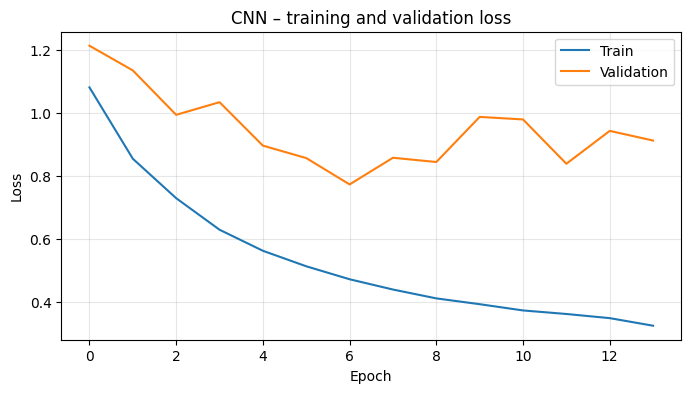

In [18]:
plt.figure(figsize=(8, 4))

plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN – training and validation loss')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

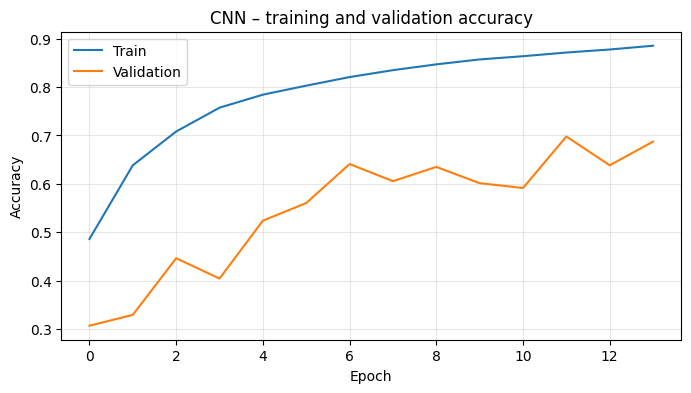

In [19]:
plt.figure(figsize=(8, 4))

plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN – training and validation accuracy')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [20]:
val_probabilities = cnn_model.predict(X_val)

y_val_pred = np.argmax(
    val_probabilities,
    axis=1
)

602/602 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [21]:
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1, 2, 3],
        target_names=CLASSES,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           N       0.88      0.69      0.77     16563
           S       0.01      0.03      0.01      1526
           V       0.77      0.93      0.84       794
           F       0.28      0.28      0.28       367

    accuracy                           0.64     19250
   macro avg       0.48      0.48      0.48     19250
weighted avg       0.80      0.64      0.71     19250



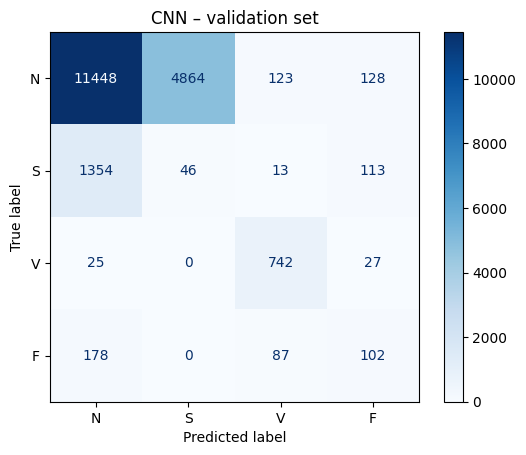

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=[0, 1, 2, 3],
    display_labels=CLASSES,
    cmap='Blues'
)

plt.title('CNN – validation set')
plt.show()

In [23]:
val_macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average='macro'
)

print(f'Validation Macro F1: {val_macro_f1:.4f}')

Validation Macro F1: 0.4773


KONIEC eksperymentu 1

In [65]:
import torch
import sys

print('Python:', sys.executable)
print('PyTorch:', torch.__version__)
print('CUDA:', torch.version.cuda)
print('CUDA available:', torch.cuda.is_available())

if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Python: d:\Users\weron\Documents\studia\aaaaa praca dypl\ecg_anomaly\venv\Scripts\python.exe
PyTorch: 2.14.1+cu126
CUDA: 12.6
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti


In [66]:
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, channels=32):
        super().__init__()

        self.conv1 = nn.Conv1d(
            channels, channels,
            kernel_size=5,
            padding=2
        )

        self.relu = nn.ReLU()

        self.conv2 = nn.Conv1d(
            channels, channels,
            kernel_size=5,
            padding=2
        )

        self.pool = nn.MaxPool1d(2)

    def forward(self, x):
        residual = x

        out = self.conv1(x)
        out = self.relu(out)
        out = self.conv2(out)

        out = out + residual
        out = self.relu(out)

        return self.pool(out)

In [67]:
RR_COLUMNS = [
    'rr_prev',
    'rr_next',
    'rr_prev_relative'
]

MERGE_COLUMNS = [
    'record_id',
    'annotation_sample'
]

rr_df = pd.read_csv('../src/rr_features.csv')

In [68]:
train_resnet_df = train_df.merge(
    rr_df,
    on=MERGE_COLUMNS,
    how='left',
    validate='one_to_one'
)

val_resnet_df = val_df.merge(
    rr_df,
    on=MERGE_COLUMNS,
    how='left',
    validate='one_to_one'
)

test_resnet_df = test_df.merge(
    rr_df,
    on=MERGE_COLUMNS,
    how='left',
    validate='one_to_one'
)

In [69]:
for name, df in [
    ('Train', train_resnet_df),
    ('Validation', val_resnet_df),
    ('Test', test_resnet_df)
]:
    print(
        name,
        'Liczba uderzeń:', len(df),
        'Brak dopasowania RR:',
        df[RR_COLUMNS].isna().all(axis=1).sum()
    )

Train Liczba uderzeń: 57203 Brak dopasowania RR: 1
Validation Liczba uderzeń: 19250 Brak dopasowania RR: 0
Test Liczba uderzeń: 24223 Brak dopasowania RR: 0


In [70]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Uzupełnianie brakujących wartości RR
rr_imputer = SimpleImputer(strategy='median')

X_rr_train = rr_imputer.fit_transform(
    train_resnet_df[RR_COLUMNS]
)

X_rr_val = rr_imputer.transform(
    val_resnet_df[RR_COLUMNS]
)

X_rr_test = rr_imputer.transform(
    test_resnet_df[RR_COLUMNS]
)

# Standaryzacja cech RR
rr_scaler = StandardScaler()

X_rr_train = rr_scaler.fit_transform(X_rr_train)
X_rr_val = rr_scaler.transform(X_rr_val)
X_rr_test = rr_scaler.transform(X_rr_test)

In [71]:
X_rr_train_torch = torch.tensor(
    X_rr_train, dtype=torch.float32
)

X_rr_val_torch = torch.tensor(
    X_rr_val, dtype=torch.float32
)

X_rr_test_torch = torch.tensor(
    X_rr_test, dtype=torch.float32
)

print("Train RR:", X_rr_train_torch.shape)
print("Validation RR:", X_rr_val_torch.shape)
print("Test RR:", X_rr_test_torch.shape)

Train RR: torch.Size([57203, 3])
Validation RR: torch.Size([19250, 3])
Test RR: torch.Size([24223, 3])


In [72]:
class ECGResNet(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.initial_conv = nn.Conv1d(
            in_channels=1,
            out_channels=32,
            kernel_size=7,
            padding=3
        )

        self.blocks = nn.Sequential(
            *[ResidualBlock(32) for _ in range(5)]
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 8 + 3, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x, rr):
        x = self.initial_conv(x)
        x = self.blocks(x)

        x = torch.flatten(x, start_dim=1)

        # Łączenie cech CNN z cechami RR
        x = torch.cat([x, rr], dim=1)

        return self.classifier(x)

In [73]:
# Sygnały EKG dla nowej sieci rezydualnej
X_resnet_train = train_resnet_df[SIGNAL_COLUMNS].to_numpy(dtype=np.float32)
X_resnet_val = val_resnet_df[SIGNAL_COLUMNS].to_numpy(dtype=np.float32)
X_resnet_test = test_resnet_df[SIGNAL_COLUMNS].to_numpy(dtype=np.float32)

# Etykiety
y_resnet_train = train_resnet_df['class'].map(class_to_idx).to_numpy()
y_resnet_val = val_resnet_df['class'].map(class_to_idx).to_numpy()
y_resnet_test = test_resnet_df['class'].map(class_to_idx).to_numpy()

In [74]:
# Parametry normalizacji wyłącznie z treningu
resnet_mean = X_resnet_train.mean()
resnet_std = X_resnet_train.std()

X_resnet_train = (X_resnet_train - resnet_mean) / resnet_std
X_resnet_val = (X_resnet_val - resnet_mean) / resnet_std
X_resnet_test = (X_resnet_test - resnet_mean) / resnet_std

In [75]:
X_resnet_train_torch = torch.tensor(
    X_resnet_train[:, None, :],
    dtype=torch.float32
)

X_resnet_val_torch = torch.tensor(
    X_resnet_val[:, None, :],
    dtype=torch.float32
)

X_resnet_test_torch = torch.tensor(
    X_resnet_test[:, None, :],
    dtype=torch.float32
)

y_resnet_train_torch = torch.tensor(
    y_resnet_train,
    dtype=torch.long
)

y_resnet_val_torch = torch.tensor(
    y_resnet_val,
    dtype=torch.long
)

y_resnet_test_torch = torch.tensor(
    y_resnet_test,
    dtype=torch.long
)

print("EKG train:", X_resnet_train_torch.shape)
print("RR train:", X_rr_train_torch.shape)
print("Etykiety train:", y_resnet_train_torch.shape)

assert len(X_resnet_train_torch) == len(X_rr_train_torch) == len(y_resnet_train_torch)
assert len(X_resnet_val_torch) == len(X_rr_val_torch) == len(y_resnet_val_torch)
assert len(X_resnet_test_torch) == len(X_rr_test_torch) == len(y_resnet_test_torch)

EKG train: torch.Size([57203, 1, 256])
RR train: torch.Size([57203, 3])
Etykiety train: torch.Size([57203])


In [77]:
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

model = ECGResNet(num_classes=4).to(device)

print('Device:', device)
print(model)

Device: cuda
ECGResNet(
  (initial_conv): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
  (blocks): Sequential(
    (0): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (relu): ReLU()
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (relu): ReLU()
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (relu): ReLU()
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (

In [78]:
dummy_input = torch.randn(
    8, 1, 256,
    device=device
)

with torch.no_grad():
    output = model(dummy_input)

print('Output shape:', output.shape)

TypeError: ECGResNet.forward() missing 1 required positional argument: 'rr'

In [29]:
X_train_torch = torch.tensor(
    X_train.transpose(0, 2, 1),
    dtype=torch.float32
)

X_val_torch = torch.tensor(
    X_val.transpose(0, 2, 1),
    dtype=torch.float32
)

X_test_torch = torch.tensor(
    X_test.transpose(0, 2, 1),
    dtype=torch.float32
)

In [30]:
y_train_torch = torch.tensor(y_train, dtype=torch.long)
y_val_torch = torch.tensor(y_val, dtype=torch.long)
y_test_torch = torch.tensor(y_test, dtype=torch.long)

In [31]:
from torch.utils.data import TensorDataset, DataLoader

In [79]:
from torch.utils.data import (
    TensorDataset,
    DataLoader,
    WeightedRandomSampler
)

BATCH_SIZE = 128

# Każda obserwacja zawiera:
# sygnał EKG, trzy cechy RR i etykietę
train_dataset = TensorDataset(
    X_resnet_train_torch,
    X_rr_train_torch,
    y_resnet_train_torch
)

val_dataset = TensorDataset(
    X_resnet_val_torch,
    X_rr_val_torch,
    y_resnet_val_torch
)

# Liczba przykładów poszczególnych klas
class_counts = np.bincount(
    y_resnet_train,
    minlength=4
)

# Wagi odwrotnie proporcjonalne do liczebności klas
class_weights = 1.0 / class_counts
sample_weights = class_weights[y_resnet_train]

# Losowanie 20 000 przykładów na epokę
sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=20000,
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True
)

signals, rr, labels = next(iter(train_loader))

print('EKG:', signals.shape)
print('RR:', rr.shape)
print('Etykiety:', labels.shape)
print('Liczebności klas:', class_counts)

EKG: torch.Size([128, 1, 256])
RR: torch.Size([128, 3])
Etykiety: torch.Size([128])
Liczebności klas: [52299   941  3906    57]


In [80]:
import torch.optim as optim

device = torch.device('cuda')

model = ECGResNet(num_classes=4).to(device)

criterion = torch.nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [34]:
NOISE_STD = 0.02

In [35]:
import copy

In [36]:
EPOCHS = 50
PATIENCE = 7

best_val_loss = float('inf')
best_model_state = None
patience_counter = 0

history = {
    'train_loss': [],
    'val_loss': [],
    'train_accuracy': [],
    'val_accuracy': []
}

In [37]:
for epoch in range(EPOCHS):

    # ===== TRAINING =====

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Augmentacja tylko podczas treningu
        inputs = inputs + torch.randn_like(inputs) * NOISE_STD

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # ===== VALIDATION =====

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    # ===== HISTORY =====

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    history['train_accuracy'].append(train_accuracy)
    history['val_accuracy'].append(val_accuracy)

    print(
        f'Epoch {epoch + 1:02d}/{EPOCHS} | '
        f'Train loss: {train_loss:.4f} | '
        f'Val loss: {val_loss:.4f} | '
        f'Train acc: {train_accuracy:.4f} | '
        f'Val acc: {val_accuracy:.4f}'
    )

    # ===== EARLY STOPPING =====

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:
            print('Early stopping')
            break

Epoch 01/50 | Train loss: 0.5159 | Val loss: 1.5270 | Train acc: 0.8031 | Val acc: 0.5441
Epoch 02/50 | Train loss: 0.1571 | Val loss: 0.6971 | Train acc: 0.9483 | Val acc: 0.8132
Epoch 03/50 | Train loss: 0.0971 | Val loss: 0.7760 | Train acc: 0.9681 | Val acc: 0.7752
Epoch 04/50 | Train loss: 0.0707 | Val loss: 1.3077 | Train acc: 0.9768 | Val acc: 0.7647
Epoch 05/50 | Train loss: 0.0542 | Val loss: 1.1233 | Train acc: 0.9824 | Val acc: 0.7830
Epoch 06/50 | Train loss: 0.0445 | Val loss: 1.0826 | Train acc: 0.9857 | Val acc: 0.7642
Epoch 07/50 | Train loss: 0.0435 | Val loss: 1.0467 | Train acc: 0.9874 | Val acc: 0.7994
Epoch 08/50 | Train loss: 0.0275 | Val loss: 1.9077 | Train acc: 0.9915 | Val acc: 0.7199
Epoch 09/50 | Train loss: 0.0305 | Val loss: 0.6808 | Train acc: 0.9898 | Val acc: 0.8835
Epoch 10/50 | Train loss: 0.0232 | Val loss: 0.9289 | Train acc: 0.9921 | Val acc: 0.8899
Epoch 11/50 | Train loss: 0.0231 | Val loss: 1.1922 | Train acc: 0.9927 | Val acc: 0.8429
Epoch 12/5

In [38]:
model.load_state_dict(best_model_state)
model.eval()

best_epoch = np.argmin(history['val_loss']) + 1

print('Najlepsza epoka:', best_epoch)
print(f'Najniższa strata walidacyjna: {best_val_loss:.4f}')

Najlepsza epoka: 9
Najniższa strata walidacyjna: 0.6808


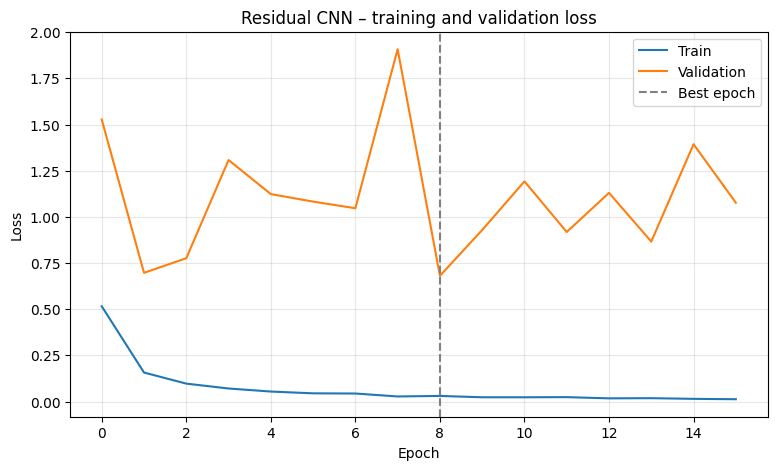

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    history['train_loss'],
    label='Train'
)

plt.plot(
    history['val_loss'],
    label='Validation'
)

plt.axvline(
    best_epoch - 1,
    color='gray',
    linestyle='--',
    label='Best epoch'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Residual CNN – training and validation loss')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

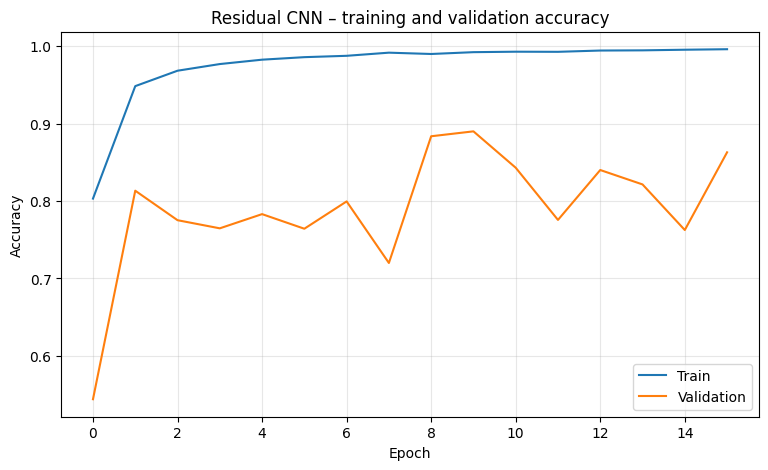

In [40]:
plt.figure(figsize=(9, 5))

plt.plot(
    history['train_accuracy'],
    label='Train'
)

plt.plot(
    history['val_accuracy'],
    label='Validation'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Residual CNN – training and validation accuracy')

plt.legend()
plt.grid(alpha=0.3)
plt.show()